In [61]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import pyplot as plt
import seaborn as sns

sns.set_theme()
from tabulate import tabulate
import pandas as pd
import numpy as np
import math

# Preparing the sample data set

## About the Iris dataset

<p style='text-align: justify;'>The iris dataset contains measurements for 150 iris flowers from three different species.</p>

The three classes in the Iris dataset:

<ol>
<li>Iris-setosa (n=50)</li>
<li>Iris-versicolor (n=50)</li>
<li>Iris-virginica (n=50)</li>
</ol>

The four features of the Iris dataset:

<ol>
<li>sepal length in cm</li>
<li>sepal width in cm</li>
<li>petal length in cm</li>
<li>petal width in cm</li>
</ol>

In [62]:
feature_dict = {
    i: label
    for i, label in zip(
        range(4),
        (
            "sepal length in cm",
            "sepal width in cm",
            "petal length in cm",
            "petal width in cm",
        ),
    )
}

## Reading in the dataset

In [63]:
df = pd.io.parsers.read_csv(
    filepath_or_buffer="https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data",
    header=None,
    sep=",",
)
df.columns = [l for i, l in sorted(feature_dict.items())] + ["class label"]
df.dropna(how="all", inplace=True)  # to drop the empty line at file-end

df.tail()

,sepal length in cm,sepal width in cm,petal length in cm,petal width in cm,class label
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica
149,5.9,3.0,5.1,1.8,Iris-virginica


$$X=\left[\begin{matrix}
x_{1}^\text{sepal length} & x_{1}^\text{sepal width} & x_{1}^\text{petal length} & x_{1}^\text{petal width}\\
x_{2}^\text{sepal length} & x_{2}^\text{sepal width} & x_{2}^\text{petal length} & x_{2}^\text{petal width}\\
\\\vdots\\
x_{150}^\text{sepal length} & x_{150}^\text{sepal width} & x_{150}^\text{petal length} & x_{150}^\text{petal width}
\end{matrix}\right]
$$

$$y=\left[\begin{matrix}
setosa\\
setosa\\
\\\vdots\\
virginica
\end{matrix}\right]$$
    
Since it is more convenient to work with numerical values, we will use the LabelEncode from the scikit-learn library to convert the class labels into numbers: 1, 2, and 3.

In [64]:
X = df[
    [
        "sepal length in cm",
        "sepal width in cm",
        "petal length in cm",
        "petal width in cm",
    ]
].values
y = df["class label"].values

enc = LabelEncoder()
label_encoder = enc.fit(y)
y = label_encoder.transform(y)

label_dict = {0: "Setosa", 1: "Versicolor", 2: "Virginica"}

In [65]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.1)

# Part I (Gaussian Discriminative Analysis)

## Generative Learning Algorithm vs Discriminative Learning Algorithm

Algorithms that try to learn mappings from input space $ \mathcal{x} $ to the output labels $\mathcal{y} $ ( such as logistic regression, linear regression, etc.) are called Discriminative Learning Algorithm(DLA). In other words, the discriminative learning algorithm tries to learn $ y $ given $ x $. Mathematically $ P(y | x) $. On the other hand, algorithm that tries to learn $ x $ given $ y $ $ (i. e. p(x | y)) $ is called Generative Learning Algorithm (GLA). Naive Bayes, Gaussian discriminant analysis are the example of GLA. While DLA tries to find a decision boundary based on the input data, GLA tries to fit a gaussian in each output label.

## Multivariate Gaussian Distribution

Gaussian Discriminant Analysis model assumes that $ p(x | y) $ is distributed according to a multivariate normal distribution, which is parameterized by a mean vector $ \mu \in \mathbb{R}^n $ and a covariance matrix $ \Sigma \in \mathbb{R}^{nxn} $, where $n$ is the number of classes. This can also be written as $ \mathcal{N}(\mu, \Sigma) $ and it's density function can be given by:

$$
p(x;\mu,\Sigma) = \frac{1}{(2\pi)^{n/2}|\Sigma|^{1/2}}exp\Bigg(-\frac{1}{2}\big(x - \mu\big)^T\Sigma^{-1}\big(x - \mu\big)\Bigg)
$$

The mean vector and covariance matrix will determine the shape of the probability density function. In the following section you can play with these parameter.

In [66]:
def multivariate_gaussian(x, mu, Sigma):
    size = len(x)
    if size == len(mu) and (size, size) == Sigma.shape:
        det = np.linalg.det(Sigma)
        inv = np.linalg.inv(Sigma)

        norm_const = 1 / (np.power(2 * np.pi, size / 2) * np.sqrt(det))

        x_mu = x - mu

        result = np.exp(-0.5 * np.dot(np.dot(x_mu.T, inv), x_mu))
        return norm_const * result
    else:
        raise NameError("The dimensions of the input don't match")

## Gaussian Discriminant Analysis(GDA) model

GDA is perfect for the case where the problem is a classificaiton problem and input variable is continious and fall into a gaussian distribution. Now lets make a flower classifier model using the iris dataset. We will apply GDA model which will model $ p(x|y) $ using a multivariate normal distribution. Iris dataset have 3 labels/class. Those are setosa, versicolor and virginica. For mathemetical modelling we will denote setosa as class 0, versicolor as class 1, virginica as class 2. During the training process at first we will calculate the class probability for each class. Class probability indicates how often data is present in the training set. For example, if we have 100 training example and class 'versicolor' appears 13 times then the class probability for class 'versicolor' will be $ \phi_1 = \frac{13}{100} = 0.13 $. So generally,

$$
\begin{align}
\phi_k = \frac{\text{number of occurance of class k}}{\text{total number of training example}} \\
       = \frac{1}{m}\sum_{i=1}^m1\{y^{(i)} = k \}
\end{align}
$$

Here m is the number of training example, k is a specific class and $ \phi_k $ represents the class probability of class k.

Now we will fit a gaussian in each of the classes. For example, if we fit a gaussian for all the training data for class 0 we get it's density function as:

$$
p(x | y=0) \sim \mathcal{N}(\mu_0, \Sigma_0)
$$

Here $ \mu_0 $ is the mean and $ \Sigma_0) $ is the covariance matrix for all the training set of class 0. More generally for class k we get the density function:

$$
p(x | y=k) \sim \mathcal{N}(\mu_k, \Sigma_k) = \frac{1}{(2\pi)^{n/2}|\Sigma_k|^{1/2}}exp\Bigg(-\frac{1}{2}\big(x - \mu_k\big)^T\Sigma_k^{-1}\big(x - \mu_k\big)\Bigg)
$$

This density function is parameterized by mean($ \mu $) and covariance matrix($ \Sigma $). So, we need to find mean and covariance matrix for all classes. We can find mean $ \mu $ and covariance matrix, $ \Sigma $ for class k using the following equation.

$$
\mu_k = \frac{\sum_{i=1}^m 1 \{y^{(i)} = k\} x^{(i)}}{\sum_{i=1}^m 1 \{y^{(i)} = k\}} \\
\Sigma = \frac{1}{m}\sum_{i=1}^m \big(x^{(i)} - \mu_{y^{(i)}}\big) \big(x^{(i)} - \mu_{y^{(i)}}\big)^T
$$

Before going into the prediction let's implement the theory that we discussed so far.

In [67]:
def fit(x_train, y_train):
    m = y_train.shape[0]  # Number of training example
    input_feature = x_train.shape[1]  # Number of input feature. In our case it's 4
    class_label = len(
        np.unique(y_train.reshape(-1))
    )  # Number of class. In our case its 3.

    # Start everything with zero first.
    # Mean for each class. Each row contains an individual class. And each of the class input is 4 dimenstional
    mu = np.zeros((class_label, input_feature))
    # Prior probability of each class.
    # Its the measure of knowing the likelihood of any class before seeing the input data.
    phi = np.zeros(class_label)

    for label in range(class_label):
        # Seperate all the training data for a single class
        indices = y_train == label

        phi[label] = np.sum(indices) / m
        mu[label] = np.mean(x_train[indices], axis=0)

    # The covariance matrix is a square symettric matrix.
    Sigma = np.zeros((input_feature, input_feature))

    for i in range(m):
        diff = x_train[i] - mu[y_train[i]]
        Sigma += np.outer(diff, diff)

    Sigma = Sigma / m

    return phi, mu, Sigma

In [68]:
phi, mu, Sigma = fit(x_train, y_train)
print("phi = ", phi)
print("mu = ", mu)
print("Sigma = ", Sigma)

phi =  [0.34074074 0.32592593 0.33333333]
mu =  [[5.0173913  3.41956522 1.46086957 0.23913043]
 [5.94772727 2.775      4.275      1.33181818]
 [6.54444444 2.98444444 5.50888889 2.03777778]]
Sigma =  [[0.25234793 0.10368858 0.15093353 0.03819498]
 [0.10368858 0.12069631 0.06291807 0.03545353]
 [0.15093353 0.06291807 0.16539637 0.04155795]
 [0.03819498 0.03545353 0.04155795 0.04170961]]


## Making prediction
Now let's assume we have some data 'x_test' that we want to predict. First we will match our data with each of the class. We will use the gaussian distribution($ \mu, \Sigma $) of the classes that we calculated during the training process. This will give us the probability of 'x_test' given in a specific class. For example, the following equation will give us the probability of x_text given the class 1.

$$
p(x\_test|y=1) = \frac{1}{(2\pi)^{n/2}|\Sigma|^{1/2}}exp\Bigg(-\frac{1}{2}\big(x\_test - \mu_1\big)^T\Sigma^{-1}\big(x\_test - \mu\big)\Bigg)
$$

We will calculate $ p(x\_test|y=k) $ for each class k, where $ k \in \{1, 2,3\} $. During the training we also calculated the class probability($ \phi $) of each of the class. We will multiply class probability with the gaussian probability to get the overall probability of a class.

$$ p(y=k|x\_test) \rightarrow p(x\_test|y=k) \times \phi_k $$

For whichever classes the probability value is higest we will consider that as the x_test's class. So we will maximize $ p(y=k|x\_test) $.

In [69]:
def predict(data, phi, mu, Sigma):

    class_label = mu.shape[0]  # Number of label we have in our case it's k = 3
    scores = np.zeros(
        class_label
    )  # Initially we set the each class probability to zero.

    # We will calculate the probability for each of the class.
    for label in range(class_label):
        scores[label] = multivariate_gaussian(data, mu[label], Sigma) * phi[label]

    prediction = np.argmax(scores)
    return prediction

In [70]:
test_cases = x_test.shape[0]
y_predict = []
items = []

for i in range(test_cases):
    prediction = predict(x_test[i], phi, mu, Sigma)
    y_predict.append(prediction)
    items.append([y_test[i], prediction])

print(tabulate(items, headers=["real class", "predicted class"]))

  real class    predicted class
------------  -----------------
           1                  1
           1                  1
           2                  2
           2                  2
           2                  2
           1                  1
           1                  1
           0                  0
           2                  2
           2                  2
           1                  1
           1                  1
           0                  0
           0                  0
           0                  0


Text(110.44999999999997, 0.5, 'predicted label')

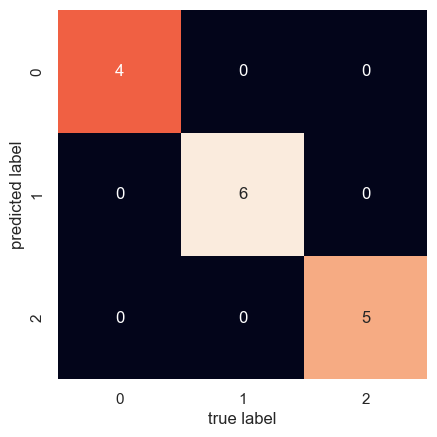

In [71]:
# confusin matrix
mat = confusion_matrix(y_test, y_predict)
sns.heatmap(
    mat.T,
    square=True,
    annot=True,
    fmt="d",
    cbar=False,
    xticklabels=np.unique(y_train.reshape(-1)),
    yticklabels=np.unique(y_train.reshape(-1)),
)
plt.xlabel("true label")
plt.ylabel("predicted label")

# Part II (Naive Bayes Implementation)

The assignment's hint indicates a **Bernoulli Naive Bayes** approach: `spam_counts[word]` and `nonspam_counts[word]` count the number of **documents containing** each word, rather than the total number of times the word occurs.

For a word \(w\),

$$
P(w\mid spam)
=
\frac{spam\_counts[w]+\alpha}
{N_{spam}+2\alpha}
$$

and similarly,

$$
P(w\mid nonspam)
=
\frac{nonspam\_counts[w]+\alpha}
{N_{nonspam}+2\alpha}.
$$

However, because we're dealing with word **presence/absence**, the probability of a document needs to account for both cases:

* word appears → $P(w\mid class)$
* word does not appear → $1-P(w\mid class)$

Using logarithms prevents numerical underflow.

A clean implementation is:

In [ ]:
import os
import math
from collections import defaultdict

alpha = 0.0000001


def load_documents(folder_path):
    """
    Load all text files in a folder.
    Each file is treated as one document.
    """

    documents = []

    for filename in os.listdir(folder_path):

        file_path = os.path.join(folder_path, filename)

        if os.path.isfile(file_path):

            with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
                documents.append(f.read())

    return documents


def get_words(document):
    """
    Return the set of unique words in a document.

    We use a set because spam_counts and nonspam_counts
    count the number of documents containing each word,
    not the total number of occurrences.
    """

    return set(document.lower().split())


def train_naive_bayes(spam_train, nonspam_train, alpha=0.0000001):

    spam_counts = defaultdict(float)
    nonspam_counts = defaultdict(float)

    vocabulary = set()

    # Count documents containing each word in spam
    for document in spam_train:

        words = get_words(document)

        for word in words:
            spam_counts[word] += 1

        vocabulary.update(words)

    # Count documents containing each word in non-spam
    for document in nonspam_train:

        words = get_words(document)

        for word in words:
            nonspam_counts[word] += 1

        vocabulary.update(words)

    n_spam = len(spam_train)
    n_nonspam = len(nonspam_train)

    # Laplace-smoothed probabilities
    spam_prob = {}
    nonspam_prob = {}

    for word in vocabulary:

        spam_prob[word] = (spam_counts[word] + alpha) / (n_spam + 2 * alpha)

        nonspam_prob[word] = (nonspam_counts[word] + alpha) / (n_nonspam + 2 * alpha)

    # Prior probabilities
    total_documents = n_spam + n_nonspam

    p_spam = n_spam / total_documents
    p_nonspam = n_nonspam / total_documents

    return (spam_prob, nonspam_prob, p_spam, p_nonspam, vocabulary)


def predict(document, model):

    spam_prob, nonspam_prob, p_spam, p_nonspam, vocabulary = model

    words = get_words(document)

    # Start with log priors
    log_spam = math.log(p_spam)
    log_nonspam = math.log(p_nonspam)

    # Bernoulli Naive Bayes:
    # consider both word presence and word absence
    for word in vocabulary:

        p_word_spam = spam_prob[word]
        p_word_nonspam = nonspam_prob[word]

        if word in words:

            log_spam += math.log(p_word_spam)
            log_nonspam += math.log(p_word_nonspam)

        else:

            log_spam += math.log(1 - p_word_spam)
            log_nonspam += math.log(1 - p_word_nonspam)

    if log_spam > log_nonspam:
        return "spam"

    return "nonspam"


def calculate_accuracy(test_documents, true_label, model):

    correct = 0

    for document in test_documents:

        prediction = predict(document, model)

        if prediction == true_label:
            correct += 1

    return correct / len(test_documents)


# Load the datasets
spam_train = load_documents("Data/spam-train")
nonspam_train = load_documents("Data/nonspam-train")

spam_test = load_documents("Data/spam-test")
nonspam_test = load_documents("Data/nonspam-test")

print("Number of spam training documents:", len(spam_train))
print("Number of non-spam training documents:", len(nonspam_train))
print("Number of spam test documents:", len(spam_test))
print("Number of non-spam test documents:", len(nonspam_test))

# Train the model
model = train_naive_bayes(spam_train, nonspam_train, alpha=alpha)

# Test the model
spam_accuracy = calculate_accuracy(spam_test, "spam", model)

nonspam_accuracy = calculate_accuracy(nonspam_test, "nonspam", model)

print("\nSpam test accuracy:", spam_accuracy)
print("Non-spam test accuracy:", nonspam_accuracy)

Number of spam training documents: 350
Number of non-spam training documents: 350
Number of spam test documents: 130
Number of non-spam test documents: 130

Spam test accuracy: 0.9692307692307692
Non-spam test accuracy: 0.9923076923076923


# Part III (Theory)

### P3 — Exponential Family and the Sigmoid Function

Using Bayes' rule,

$$
p(y=1\mid x)
=
\frac{p(x\mid y=1)p(y=1)}
{p(x\mid y=1)p(y=1)+p(x\mid y=0)p(y=0)}.
$$

It is convenient to consider the odds:

$$
\frac{p(y=1\mid x)}{p(y=0\mid x)}
=
\frac{p(x\mid y=1)p(y=1)}
{p(x\mid y=0)p(y=0)}.
$$

Since both class-conditional distributions belong to the exponential family,

$$
p(x\mid y=1)
=
h(x)\exp\left(
\eta_1^\top T(x)-A(\eta_1)
\right)
$$

and

$$
p(x\mid y=0)
=
h(x)\exp\left(
\eta_0^\top T(x)-A(\eta_0)
\right).
$$

Therefore,

$$
\begin{aligned}
\frac{p(x\mid y=1)}{p(x\mid y=0)}
&=
\exp\left(
\eta_1^\top T(x)-A(\eta_1)
-\eta_0^\top T(x)+A(\eta_0)
\right)\\
&=
\exp\left(
(\eta_1-\eta_0)^\top T(x)
-A(\eta_1)+A(\eta_0)
\right).
\end{aligned}
$$

Hence,

$$
\frac{p(y=1\mid x)}{p(y=0\mid x)}
=
\frac{p(y=1)}{p(y=0)}
\exp\left(
(\eta_1-\eta_0)^\top T(x)
-A(\eta_1)+A(\eta_0)
\right).
$$

Taking the logarithm,

$$
\log
\frac{p(y=1\mid x)}{p(y=0\mid x)}
=
(\eta_1-\eta_0)^\top T(x)
-A(\eta_1)+A(\eta_0)
+\log\frac{p(y=1)}{p(y=0)}.
$$

Define

$$
\theta=\eta_1-\eta_0
$$

and

$$
b=
-A(\eta_1)+A(\eta_0)
+\log\frac{p(y=1)}{p(y=0)}.
$$

Then

$$
\log
\frac{p(y=1\mid x)}{p(y=0\mid x)}
=
\theta^\top T(x)+b.
$$

Since

$$
p(y=0\mid x)=1-p(y=1\mid x),
$$

we obtain

$$
\frac{p(y=1\mid x)}
{1-p(y=1\mid x)}
=
e^{\theta^\top T(x)+b}.
$$

Solving for $p(y=1\mid x)$,

$$
\begin{aligned}
p(y=1\mid x)
&=
\frac{e^{\theta^\top T(x)+b}}
{1+e^{\theta^\top T(x)+b}}\\
&=
\frac{1}
{1+e^{-(\theta^\top T(x)+b)}}\\
&=
\sigma\left(\theta^\top T(x)+b\right).
\end{aligned}
$$

Thus,

$$
\boxed{
p(y=1\mid x)
=
\sigma\left(\theta^\top T(x)+b\right)
}
$$

where

$$
\boxed{\theta=\eta_1-\eta_0}
$$

and

$$
\boxed{
b=
-A(\eta_1)+A(\eta_0)
+\log\frac{p(y=1)}{p(y=0)}
}.
$$

If the sufficient statistic is $T(x)=x$, this becomes

$$
\boxed{
p(y=1\mid x)
=
\sigma\left(\theta^\top x+b\right)
}.
$$